## Cell 1 — Install Dependencies

In [ ]:
!pip install segmentation-models-pytorch -q
!pip install tqdm -q
print("✓ Dependencies installed")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00
✓ Dependencies installed


## Cell 2 — Mount Drive & Set Paths

In [ ]:
from google.colab import drive
import os

# Mount if not already mounted
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
else:
    print("✓ Drive already mounted")

# ── All paths — Account 1 Drive structure ────────────────────────────────────
DRIVE_SERVER  = '/content/drive/MyDrive/BraTS2024_Server'

FEAT_3D_PATH  = '/content/drive/MyDrive/BraTS2024_3DUNet/features/feat_3d_round1.pt'
FEAT_2D_PATH  = '/content/drive/MyDrive/BraTS2024_3DUNet/features/feat_2d_round1.pt'
MASK_DIR      = '/content/drive/MyDrive/BraTS2024_3DUNet/preprocessed/masks'

SAVE_PATH     = os.path.join(DRIVE_SERVER, 'server_round1.tar')
GUID_PATH     = os.path.join(DRIVE_SERVER, 'guidance_round1.pt')

os.makedirs(DRIVE_SERVER, exist_ok=True)

print(f"✓ Server base     : {DRIVE_SERVER}")
print(f"  feat_3d path    : {FEAT_3D_PATH}")
print(f"  feat_2d path    : {FEAT_2D_PATH}")
print(f"  mask dir        : {MASK_DIR}")
print(f"  masks exist     : {os.path.exists(MASK_DIR)}")
print(f"  feat_3d exists  : {os.path.exists(FEAT_3D_PATH)}")
print(f"  feat_2d exists  : {os.path.exists(FEAT_2D_PATH)}")


Mounted at /content/drive
✓ Server base     : /content/drive/MyDrive/BraTS2024_Server
  feat_3d path    : /content/drive/MyDrive/BraTS2024_3DUNet/features/feat_3d_round1.pt
  feat_2d path    : /content/drive/MyDrive/BraTS2024_3DUNet/features/feat_2d_round1.pt
  mask dir        : /content/drive/MyDrive/BraTS2024_3DUNet/preprocessed/masks
  masks exist     : True
  feat_3d exists  : True
  feat_2d exists  : True


## Cell 3 — Imports

In [ ]:
import os, gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✓ Device  : {DEVICE}")
print(f"  PyTorch : {torch.__version__}")
if torch.cuda.is_available():
    print(f"  GPU     : {torch.cuda.get_device_name(0)}")
    print(f"  VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("  ⚠ WARNING: No GPU detected!")
    print("  Go to Runtime → Change runtime type → T4 GPU and restart")


✓ Device  : cuda
  PyTorch : 2.10.0+cu128
  GPU     : Tesla T4
  VRAM    : 15.6 GB


## Cell 4 — Load Feature Files

In [ ]:
feat_3d = torch.load(FEAT_3D_PATH, map_location='cpu')
feat_2d = torch.load(FEAT_2D_PATH, map_location='cpu')

assert feat_3d.shape == (20, 256, 16, 16, 16), f"feat_3d wrong shape: {feat_3d.shape}"
assert feat_2d.shape == (20, 256, 16, 16, 16), f"feat_2d wrong shape: {feat_2d.shape}"

print(f"✓ feat_3d_round1  shape: {feat_3d.shape}  "
      f"size: {feat_3d.element_size() * feat_3d.nelement() / 1e6:.1f} MB")
print(f"✓ feat_2d_round1  shape: {feat_2d.shape}  "
      f"size: {feat_2d.element_size() * feat_2d.nelement() / 1e6:.1f} MB")
print(f"✓ Both files loaded and verified")


✓ feat_3d_round1  shape: torch.Size([20, 256, 16, 16, 16])  size: 83.9 MB
✓ feat_2d_round1  shape: torch.Size([20, 256, 16, 16, 16])  size: 83.9 MB
✓ Both files loaded and verified


## Cell 5 — Load Segmentation Masks

In [ ]:
mask_files = sorted(os.listdir(MASK_DIR))[:20]
print(f"✓ Mask dir  : {MASK_DIR}")
print(f"  Files     : {len(mask_files)}")
print(f"  First     : {mask_files[0]}")
print(f"  Last      : {mask_files[-1]}")

all_masks = []
for fname in tqdm(mask_files, desc="Loading masks"):
    mask = np.load(os.path.join(MASK_DIR, fname))            # (H,W,D,4)
    mask = torch.from_numpy(mask).permute(3, 2, 0, 1).float()# (4,D,H,W)

    if mask.shape[1:] != (128, 128, 128):
        mask = F.interpolate(
            mask.unsqueeze(0), size=(128, 128, 128), mode='nearest'
        ).squeeze(0)

    all_masks.append(mask.unsqueeze(0))   # (1,4,128,128,128)

masks = torch.cat(all_masks, dim=0)       # (20,4,128,128,128)
print(f"\n✓ Masks tensor   : {masks.shape}")
print(f"  Classes present : {masks.argmax(dim=1).unique().tolist()}")
print(f"  Tumor fraction  : "
      f"{(masks.argmax(dim=1) > 0).float().mean().item()*100:.1f}%")


✓ Mask dir  : /content/drive/MyDrive/BraTS2024_3DUNet/preprocessed/masks
  Files     : 20
  First     : mask_0000.npy
  Last      : mask_0023.npy


Loading masks: 100%|██████████| 20/20 [00:28<00:00,  1.41s/it]



✓ Masks tensor   : torch.Size([20, 4, 128, 128, 128])
  Classes present : [0, 1, 2, 3]
  Tumor fraction  : 4.0%


## Cell 6 — Meta-Fusion Server Model

In [ ]:
class MetaFusionServer(nn.Module):

    def __init__(self):
        super().__init__()

        # Alignment blocks — learn shared representational space per client
        self.align_3d = nn.Sequential(
            nn.Conv3d(256, 256, kernel_size=1),
            nn.BatchNorm3d(256),
            nn.ReLU(inplace=True)
        )
        self.align_2d = nn.Sequential(
            nn.Conv3d(256, 256, kernel_size=1),
            nn.BatchNorm3d(256),
            nn.ReLU(inplace=True)
        )

        # Fusion blocks — learn cross-modal patterns
        self.fusion1 = nn.Sequential(
            nn.Conv3d(512, 256, kernel_size=3, padding=1),
            nn.BatchNorm3d(256),
            nn.ReLU(inplace=True)
        )
        self.fusion2 = nn.Sequential(
            nn.Conv3d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),
            nn.Dropout3d(0.1)
        )
        self.fusion3 = nn.Sequential(
            nn.Conv3d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True)
        )

        # Segmentation head — training supervision only, NOT sent to clients
        self.seg_head = nn.Sequential(
            nn.Upsample(scale_factor=8, mode='trilinear', align_corners=True),
            nn.Conv3d(64, 4, kernel_size=1)
        )

        # Guidance head — output sent back to both clients each round
        self.guidance_head = nn.Sequential(
            nn.Conv3d(64, 256, kernel_size=1),
            nn.ReLU(inplace=True)
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv3d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out',
                                        nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm3d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, feat_3d, feat_2d):
        # Align each client stream
        a3 = self.align_3d(feat_3d)            # (B, 256, 16, 16, 16)
        a2 = self.align_2d(feat_2d)            # (B, 256, 16, 16, 16)

        # Concatenate and fuse
        x = torch.cat([a3, a2], dim=1)         # (B, 512, 16, 16, 16)
        x = self.fusion1(x)                    # (B, 256, 16, 16, 16)
        x = self.fusion2(x)                    # (B, 128, 16, 16, 16)
        x = self.fusion3(x)                    # (B,  64, 16, 16, 16)

        seg_out  = self.seg_head(x)            # (B,   4, 128, 128, 128)
        guidance = self.guidance_head(x)       # (B, 256,  16,  16,  16)

        return seg_out, guidance


# ── Verify ────────────────────────────────────────────────────────────────────
server = MetaFusionServer().to(DEVICE)
total_params = sum(p.numel() for p in server.parameters())

with torch.no_grad():
    f3t = torch.randn(2, 256, 16, 16, 16).to(DEVICE)
    f2t = torch.randn(2, 256, 16, 16, 16).to(DEVICE)
    seg_t, gui_t = server(f3t, f2t)

assert seg_t.shape == (2,   4, 128, 128, 128), f"seg wrong: {seg_t.shape}"
assert gui_t.shape == (2, 256,  16,  16,  16), f"guidance wrong: {gui_t.shape}"

print(f"✓ MetaFusionServer verified")
print(f"  feat_3d input : {f3t.shape}")
print(f"  feat_2d input : {f2t.shape}")
print(f"  seg_out       : {seg_t.shape}")
print(f"  guidance      : {gui_t.shape}")
print(f"  Total params  : {total_params:,}")

del f3t, f2t, seg_t, gui_t
free_memory()


✓ MetaFusionServer verified
  feat_3d input : torch.Size([2, 256, 16, 16, 16])
  feat_2d input : torch.Size([2, 256, 16, 16, 16])
  seg_out       : torch.Size([2, 4, 128, 128, 128])
  guidance      : torch.Size([2, 256, 16, 16, 16])
  Total params  : 4,795,716


## Cell 7 — Loss Functions

In [ ]:
_dice_loss  = smp.losses.DiceLoss(
    mode='multiclass', from_logits=True, smooth=1e-5, eps=1e-7
)
_focal_loss = smp.losses.FocalLoss(
    mode='multiclass', alpha=0.25, gamma=2.0
)

def server_loss(seg_out, target_onehot):
    """
    seg_out       : (B, 4, 128, 128, 128) raw logits
    target_onehot : (B, 4, 128, 128, 128) one-hot float
    """
    target_cls = target_onehot.argmax(dim=1)   # (B, 128, 128, 128)
    return _dice_loss(seg_out, target_cls) + _focal_loss(seg_out, target_cls)

print("✓ Loss functions ready — Dice + Focal")


✓ Loss functions ready — Dice + Focal


## Cell 8 — Train Meta-Fusion Server

Training Meta-Fusion Server — 100 epochs on cuda
  [001/100]  Loss: 1.9539  LR: 0.001000
  [010/100]  Loss: 0.4304  LR: 0.000976
  [020/100]  Loss: 0.3549  LR: 0.000905
  [030/100]  Loss: 0.3075  LR: 0.000794
  [040/100]  Loss: 0.2823  LR: 0.000655
  [050/100]  Loss: 0.2449  LR: 0.000501
  [060/100]  Loss: 0.2258  LR: 0.000346
  [070/100]  Loss: 0.2075  LR: 0.000207
  [080/100]  Loss: 0.2008  LR: 0.000096
  [090/100]  Loss: 0.1958  LR: 0.000025
  [100/100]  Loss: 0.1949  LR: 0.000001

✓ Training complete
  Best loss  : 0.1949
  Saved      : /content/drive/MyDrive/BraTS2024_Server/server_round1.tar


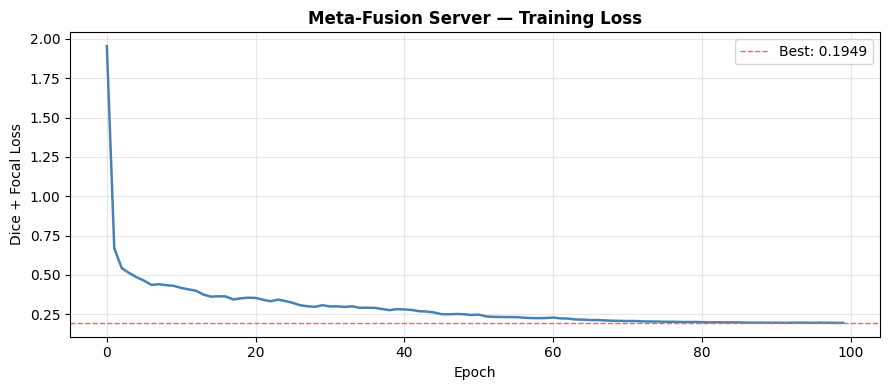

✓ Loss curve saved to Drive


In [ ]:
EPOCHS = 100
LR     = 1e-3

optimizer = torch.optim.Adam(server.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)

# Move all data to device once
feat_3d_dev = feat_3d.to(DEVICE)   # (20, 256, 16, 16, 16)
feat_2d_dev = feat_2d.to(DEVICE)   # (20, 256, 16, 16, 16)
masks_dev   = masks.to(DEVICE)     # (20, 4, 128, 128, 128)

print(f"Training Meta-Fusion Server — {EPOCHS} epochs on {DEVICE}")
print(f"{'='*55}")

best_loss    = float('inf')
loss_history = []

for epoch in range(1, EPOCHS + 1):
    server.train()
    epoch_loss = 0.0

    for i in range(20):
        f3 = feat_3d_dev[i].unsqueeze(0)   # (1, 256, 16, 16, 16)
        f2 = feat_2d_dev[i].unsqueeze(0)   # (1, 256, 16, 16, 16)
        m  = masks_dev[i].unsqueeze(0)     # (1, 4, 128, 128, 128)

        optimizer.zero_grad()
        seg_out, _ = server(f3, f2)
        loss = server_loss(seg_out, m)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(server.parameters(), 1.0)
        optimizer.step()

        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / 20
    loss_history.append(avg_loss)

    if epoch % 10 == 0 or epoch == 1:
        lr_now = optimizer.param_groups[0]['lr']
        print(f"  [{epoch:03d}/{EPOCHS}]  Loss: {avg_loss:.4f}  LR: {lr_now:.6f}")

    # Save best checkpoint
    if avg_loss < best_loss:
        best_loss = avg_loss
        torch.save({
            'epoch'    : epoch,
            'model'    : server.state_dict(),
            'optimizer': optimizer.state_dict(),
            'loss'     : avg_loss,
        }, SAVE_PATH)

print(f"\n✓ Training complete")
print(f"  Best loss  : {best_loss:.4f}")
print(f"  Saved      : {SAVE_PATH}")

# Plot
plt.figure(figsize=(9, 4))
plt.plot(loss_history, color='steelblue', linewidth=1.8)
plt.axhline(best_loss, color='tomato', linestyle='--',
            linewidth=1, label=f'Best: {best_loss:.4f}')
plt.title("Meta-Fusion Server — Training Loss", fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Dice + Focal Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(DRIVE_SERVER, 'server_loss.png'), dpi=120)
plt.show()
print(f"✓ Loss curve saved to Drive")


## Cell 9 — Extract Guidance Signal

In [ ]:
# Load best checkpoint
ckpt = torch.load(SAVE_PATH, map_location=DEVICE)
server.load_state_dict(ckpt['model'])
server.eval()
print(f"✓ Loaded best checkpoint")
print(f"  Epoch : {ckpt['epoch']}")
print(f"  Loss  : {ckpt['loss']:.4f}")

# Extract guidance for all 20 volumes
all_guidance = []

with torch.no_grad():
    for i in range(20):
        f3 = feat_3d_dev[i].unsqueeze(0)    # (1, 256, 16, 16, 16)
        f2 = feat_2d_dev[i].unsqueeze(0)    # (1, 256, 16, 16, 16)
        _, guidance = server(f3, f2)        # (1, 256, 16, 16, 16)
        all_guidance.append(guidance.cpu())
        print(f"  [{i+1:02d}/20] guidance shape: {guidance.shape}")

guidance_round1 = torch.cat(all_guidance, dim=0)   # (20, 256, 16, 16, 16)
torch.save(guidance_round1, GUID_PATH)

print(f"\n✓ guidance_round1.pt saved")
print(f"  Shape : {guidance_round1.shape}")
print(f"  Size  : {guidance_round1.element_size() * guidance_round1.nelement() / 1e6:.1f} MB")
print(f"  Path  : {GUID_PATH}")


✓ Loaded best checkpoint
  Epoch : 100
  Loss  : 0.1949
  [01/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [02/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [03/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [04/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [05/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [06/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [07/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [08/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [09/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [10/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [11/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [12/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [13/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [14/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [15/20] guidance shape: torch.Size([1, 256, 16, 16, 16])
  [16/20] guidance shape: torch.Size([1, 256, 16, 16, 16])


## Cell 10 — Verify & Share

In [ ]:
# Final verification
g = torch.load(GUID_PATH, map_location='cpu')
assert g.shape == (20, 256, 16, 16, 16), f"Wrong shape: {g.shape}"

print(f"✓ guidance_round1.pt verified")
print(f"  Shape  : {g.shape}")
print(f"  Min    : {g.min():.4f}")
print(f"  Max    : {g.max():.4f}")
print(f"  Mean   : {g.mean():.4f}")
print(f"  Std    : {g.std():.4f}")
del g
free_memory()

print(f"""
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  SERVER ROUND 1 COMPLETE
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  guidance_round1.pt saved to:
  {GUID_PATH}

  Next steps:
  1. Share guidance_round1.pt with Account 1
     → Right click in Drive → Share → Anyone with link
     → Copy link → send to Account 1

  2. Account 1 (Client 1 — 3D U-Net)
     → Load guidance_round1.pt
     → Fine-tune 10 epochs  (Round 2)
     → Extract feat_3d_round2.pt

  3. Account 2 (Client 2 — DeepLabV3+)
     → Load guidance_round1.pt  (already here)
     → Fine-tune 10 epochs  (Round 2)
     → Extract feat_2d_round2.pt

  4. Server Round 2
     → Load both round2 feature files
     → Update fusion module
     → Produce guidance_round2.pt

  5. Both clients Round 3 (10 epochs each)
  6. Server final update
  7. Final evaluation on 80 test patients
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")


✓ guidance_round1.pt verified
  Shape  : torch.Size([20, 256, 16, 16, 16])
  Min    : 0.0000
  Max    : 14.7007
  Mean   : 0.1783
  Std    : 0.3144

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  SERVER ROUND 1 COMPLETE
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  guidance_round1.pt saved to:
  /content/drive/MyDrive/BraTS2024_Server/guidance_round1.pt

  Next steps:
  1. Share guidance_round1.pt with Account 1
     → Right click in Drive → Share → Anyone with link
     → Copy link → send to Account 1

  2. Account 1 (Client 1 — 3D U-Net)
     → Load guidance_round1.pt
     → Fine-tune 10 epochs  (Round 2)
     → Extract feat_3d_round2.pt

  3. Account 2 (Client 2 — DeepLabV3+)
     → Load guidance_round1.pt  (already here)
     → Fine-tune 10 epochs  (Round 2)
     → Extract feat_2d_round2.pt

  4. Server Round 2
     → Load both round2 feature files
     → Update fusion module
     → Produce guidance_round2.pt

  5. Both clients Round 3 (10 epochs each)
  6. Server final up

In [ ]:
import gdown, os, torch, gc
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

!pip install segmentation-models-pytorch -q
import segmentation_models_pytorch as smp

DEVICE       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DRIVE_SERVER = '/content/drive/MyDrive/BraTS2024_Server'
MASK_DIR     = '/content/drive/MyDrive/BraTS2024_3DUNet/preprocessed/masks'

FEAT_3D_R2   = '/content/drive/MyDrive/BraTS2024_3DUNet/features/feat_3d_round2.pt'
FEAT_2D_R2   = '/content/drive/MyDrive/BraTS2024_3DUNet/features/feat_2d_round2.pt'
SERVER_R1    = os.path.join(DRIVE_SERVER, 'server_round1.tar')
SERVER_R2    = os.path.join(DRIVE_SERVER, 'server_round2.tar')
GUID_R2_PATH = os.path.join(DRIVE_SERVER, 'guidance_round2.pt')

def free_memory():
    gc.collect()
    torch.cuda.empty_cache()

# Download feat_3d_round2.pt
if not os.path.exists(FEAT_3D_R2):
    print("Downloading feat_3d_round2.pt...")
    gdown.download(
        "https://drive.google.com/uc?id=1OXM1sYTB-LrXgwxphx6DG4mwZ53C9QQK",
        FEAT_3D_R2, quiet=False
    )
else:
    print(f"✓ feat_3d_round2.pt already exists")

# Download feat_2d_round2.pt
if not os.path.exists(FEAT_2D_R2):
    print("Downloading feat_2d_round2.pt...")
    gdown.download(
        "https://drive.google.com/uc?id=1iQqyVbi5dWYZBOHoJQWrXVm25BJTgVG4",
        FEAT_2D_R2, quiet=False
    )
else:
    print(f"✓ feat_2d_round2.pt already exists")

# Verify
f3 = torch.load(FEAT_3D_R2, map_location='cpu')
f2 = torch.load(FEAT_2D_R2, map_location='cpu')
assert f3.shape == (20, 256, 16, 16, 16), f"Wrong shape: {f3.shape}"
assert f2.shape == (20, 256, 16, 16, 16), f"Wrong shape: {f2.shape}"
print(f"✓ feat_3d_round2 : {f3.shape}")
print(f"✓ feat_2d_round2 : {f2.shape}")
print(f"✓ Device         : {DEVICE}")
del f3, f2

✓ feat_3d_round2.pt already exists


Downloading...
From (original): https://drive.google.com/uc?id=1iQqyVbi5dWYZBOHoJQWrXVm25BJTgVG4
From (redirected): https://drive.google.com/uc?id=1iQqyVbi5dWYZBOHoJQWrXVm25BJTgVG4&confirm=t&uuid=b5ed75d2-a4ad-4ad8-b67c-37a4a45a146b
To: /content/drive/MyDrive/BraTS2024_3DUNet/features/feat_2d_round2.pt
100%|██████████| 83.9M/83.9M [00:01<00:00, 68.9MB/s]


✓ feat_3d_round2 : torch.Size([20, 256, 16, 16, 16])
✓ feat_2d_round2 : torch.Size([20, 256, 16, 16, 16])
✓ Device         : cuda


## Cell to Mount Google Drive

This cell explicitly mounts your Google Drive, ensuring that the Colab environment can access files stored in your Drive, such as the feature files required for this notebook.

In [ ]:
from google.colab import drive
import os

# Mount if not already mounted
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
else:
    print("✓ Drive already mounted")

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:
feat_3d_r2 = torch.load(FEAT_3D_R2, map_location='cpu')
feat_2d_r2 = torch.load(FEAT_2D_R2, map_location='cpu')

mask_files = sorted(os.listdir(MASK_DIR))[:20]
all_masks  = []
for fname in mask_files:
    mask = np.load(os.path.join(MASK_DIR, fname))
    mask = torch.from_numpy(mask).permute(3, 2, 0, 1).float()
    if mask.shape[1:] != (128, 128, 128):
        mask = F.interpolate(
            mask.unsqueeze(0), size=(128,128,128), mode='nearest'
        ).squeeze(0)
    all_masks.append(mask.unsqueeze(0))

masks_r2 = torch.cat(all_masks, dim=0)
print(f"✓ feat_3d_round2 : {feat_3d_r2.shape}")
print(f"✓ feat_2d_round2 : {feat_2d_r2.shape}")
print(f"✓ Masks          : {masks_r2.shape}")

✓ feat_3d_round2 : torch.Size([20, 256, 16, 16, 16])
✓ feat_2d_round2 : torch.Size([20, 256, 16, 16, 16])
✓ Masks          : torch.Size([20, 4, 128, 128, 128])


In [ ]:
class MetaFusionServer(nn.Module):
    def __init__(self):
        super().__init__()
        self.align_3d = nn.Sequential(
            nn.Conv3d(256, 256, 1), nn.BatchNorm3d(256), nn.ReLU(inplace=True))
        self.align_2d = nn.Sequential(
            nn.Conv3d(256, 256, 1), nn.BatchNorm3d(256), nn.ReLU(inplace=True))
        self.fusion1  = nn.Sequential(
            nn.Conv3d(512, 256, 3, padding=1), nn.BatchNorm3d(256), nn.ReLU(inplace=True))
        self.fusion2  = nn.Sequential(
            nn.Conv3d(256, 128, 3, padding=1), nn.BatchNorm3d(128),
            nn.ReLU(inplace=True), nn.Dropout3d(0.1))
        self.fusion3  = nn.Sequential(
            nn.Conv3d(128, 64, 3, padding=1), nn.BatchNorm3d(64), nn.ReLU(inplace=True))
        self.seg_head = nn.Sequential(
            nn.Upsample(scale_factor=8, mode='trilinear', align_corners=True),
            nn.Conv3d(64, 4, 1))
        self.guidance_head = nn.Sequential(
            nn.Conv3d(64, 256, 1), nn.ReLU(inplace=True))
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv3d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm3d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, f3, f2):
        x = torch.cat([self.align_3d(f3), self.align_2d(f2)], dim=1)
        x = self.fusion3(self.fusion2(self.fusion1(x)))
        return self.seg_head(x), self.guidance_head(x)

# Load Round 1 weights as starting point
server   = MetaFusionServer().to(DEVICE)
r1_ckpt  = torch.load(SERVER_R1, map_location=DEVICE)
server.load_state_dict(r1_ckpt['model'])
print(f"✓ Server loaded from Round 1 checkpoint")
print(f"  Epoch : {r1_ckpt['epoch']}  Loss : {r1_ckpt['loss']:.4f}")
print(f"  Starting Round 2 update from Round 1 weights")

✓ Server loaded from Round 1 checkpoint
  Epoch : 100  Loss : 0.1949
  Starting Round 2 update from Round 1 weights


Training Server Round 2 — 100 epochs
Using Round 2 features (richer — both clients saw guidance)
  [001/100]  Loss: 0.5544  LR: 0.000500
  [010/100]  Loss: 0.2841  LR: 0.000488
  [020/100]  Loss: 0.2521  LR: 0.000452
  [030/100]  Loss: 0.2293  LR: 0.000397
  [040/100]  Loss: 0.2216  LR: 0.000328
  [050/100]  Loss: 0.1969  LR: 0.000251
  [060/100]  Loss: 0.1890  LR: 0.000173
  [070/100]  Loss: 0.1844  LR: 0.000104
  [080/100]  Loss: 0.1801  LR: 0.000049
  [090/100]  Loss: 0.1797  LR: 0.000013
  [100/100]  Loss: 0.1787  LR: 0.000001

✓ Server Round 2 training complete
  Best loss : 0.1777
  Saved     : /content/drive/MyDrive/BraTS2024_Server/server_round2.tar


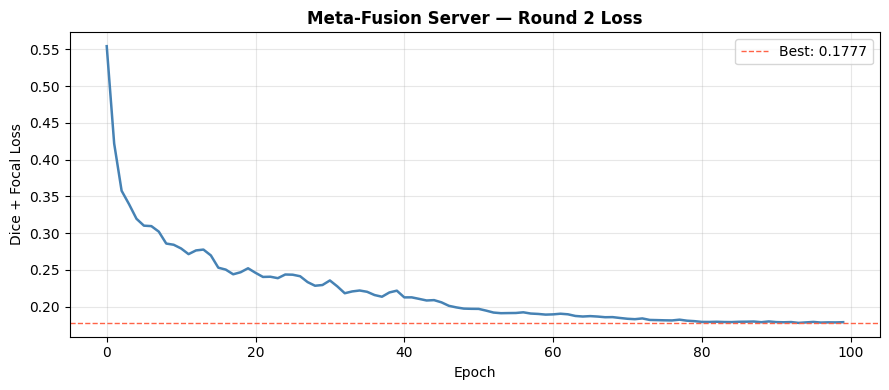

In [ ]:
_dice_loss  = smp.losses.DiceLoss(
    mode='multiclass', from_logits=True, smooth=1e-5, eps=1e-7)
_focal_loss = smp.losses.FocalLoss(
    mode='multiclass', alpha=0.25, gamma=2.0)

def server_loss(seg_out, target_onehot):
    target_cls = target_onehot.argmax(dim=1)
    return _dice_loss(seg_out, target_cls) + _focal_loss(seg_out, target_cls)

EPOCHS    = 100
LR        = 5e-4   # lower than Round 1 — fine-tuning from R1 weights

optimizer = torch.optim.Adam(server.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6)

feat_3d_dev = feat_3d_r2.to(DEVICE)
feat_2d_dev = feat_2d_r2.to(DEVICE)
masks_dev   = masks_r2.to(DEVICE)

print(f"Training Server Round 2 — {EPOCHS} epochs")
print(f"Using Round 2 features (richer — both clients saw guidance)")
print("=" * 60)

best_loss    = float('inf')
loss_history = []

for epoch in range(1, EPOCHS + 1):
    server.train()
    epoch_loss = 0.0

    for i in range(20):
        f3 = feat_3d_dev[i].unsqueeze(0)
        f2 = feat_2d_dev[i].unsqueeze(0)
        m  = masks_dev[i].unsqueeze(0)

        optimizer.zero_grad()
        seg_out, _ = server(f3, f2)
        loss = server_loss(seg_out, m)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(server.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / 20
    loss_history.append(avg_loss)

    if epoch % 10 == 0 or epoch == 1:
        print(f"  [{epoch:03d}/{EPOCHS}]  "
              f"Loss: {avg_loss:.4f}  "
              f"LR: {optimizer.param_groups[0]['lr']:.6f}")

    if avg_loss < best_loss:
        best_loss = avg_loss
        torch.save({
            'epoch'    : epoch,
            'model'    : server.state_dict(),
            'optimizer': optimizer.state_dict(),
            'loss'     : avg_loss,
        }, SERVER_R2)

print(f"\n✓ Server Round 2 training complete")
print(f"  Best loss : {best_loss:.4f}")
print(f"  Saved     : {SERVER_R2}")

plt.figure(figsize=(9, 4))
plt.plot(loss_history, color='steelblue', linewidth=1.8)
plt.axhline(best_loss, color='tomato', linestyle='--',
            linewidth=1, label=f'Best: {best_loss:.4f}')
plt.title("Meta-Fusion Server — Round 2 Loss", fontweight='bold')
plt.xlabel("Epoch"); plt.ylabel("Dice + Focal Loss")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(DRIVE_SERVER, 'server_r2_loss.png'), dpi=120)
plt.show()

In [ ]:
ckpt = torch.load(SERVER_R2, map_location=DEVICE)
server.load_state_dict(ckpt['model'])
server.eval()
print(f"✓ Best R2 checkpoint — epoch {ckpt['epoch']}  loss {ckpt['loss']:.4f}")

all_guidance = []
with torch.no_grad():
    for i in range(20):
        f3 = feat_3d_dev[i].unsqueeze(0)
        f2 = feat_2d_dev[i].unsqueeze(0)
        _, guidance = server(f3, f2)
        all_guidance.append(guidance.cpu())
        print(f"  [{i+1:02d}/20] {guidance.shape}")

guidance_round2 = torch.cat(all_guidance, dim=0)
torch.save(guidance_round2, GUID_R2_PATH)

print(f"\n✓ guidance_round2.pt saved")
print(f"  Shape : {guidance_round2.shape}")
print(f"  Min   : {guidance_round2.min():.4f}")
print(f"  Max   : {guidance_round2.max():.4f}")
print(f"  Mean  : {guidance_round2.mean():.4f}")
print(f"  Std   : {guidance_round2.std():.4f}")
print(f"  Path  : {GUID_R2_PATH}")

# Compare Round 1 vs Round 2 guidance
guid_r1 = torch.load(
    os.path.join(DRIVE_SERVER, 'guidance_round1.pt'), map_location='cpu')
guid_r2 = torch.load(GUID_R2_PATH, map_location='cpu')

print(f"\nGuidance Comparison:")
print(f"{'Metric':<10} {'Round 1':>12} {'Round 2':>12} {'Change':>12}")
print("-" * 48)
for name, fn in [("Min", torch.min), ("Max", torch.max),
                  ("Mean", torch.mean), ("Std", torch.std)]:
    v1 = fn(guid_r1).item()
    v2 = fn(guid_r2).item()
    print(f"{name:<10} {v1:>12.4f} {v2:>12.4f} {v2-v1:>+12.4f}")

del guid_r1, guid_r2
free_memory()
print(f"\n✓ Server Round 2 complete — disconnect when done")

✓ Best R2 checkpoint — epoch 94  loss 0.1777
  [01/20] torch.Size([1, 256, 16, 16, 16])
  [02/20] torch.Size([1, 256, 16, 16, 16])
  [03/20] torch.Size([1, 256, 16, 16, 16])
  [04/20] torch.Size([1, 256, 16, 16, 16])
  [05/20] torch.Size([1, 256, 16, 16, 16])
  [06/20] torch.Size([1, 256, 16, 16, 16])
  [07/20] torch.Size([1, 256, 16, 16, 16])
  [08/20] torch.Size([1, 256, 16, 16, 16])
  [09/20] torch.Size([1, 256, 16, 16, 16])
  [10/20] torch.Size([1, 256, 16, 16, 16])
  [11/20] torch.Size([1, 256, 16, 16, 16])
  [12/20] torch.Size([1, 256, 16, 16, 16])
  [13/20] torch.Size([1, 256, 16, 16, 16])
  [14/20] torch.Size([1, 256, 16, 16, 16])
  [15/20] torch.Size([1, 256, 16, 16, 16])
  [16/20] torch.Size([1, 256, 16, 16, 16])
  [17/20] torch.Size([1, 256, 16, 16, 16])
  [18/20] torch.Size([1, 256, 16, 16, 16])
  [19/20] torch.Size([1, 256, 16, 16, 16])
  [20/20] torch.Size([1, 256, 16, 16, 16])

✓ guidance_round2.pt saved
  Shape : torch.Size([20, 256, 16, 16, 16])
  Min   : 0.0000
  Max 